Compare active and idle states of IOT devices

Code structure: if possible have data and display independent, so that time can be saved by not recomputing unchanged data

e.g

```python
show_data(get_data())
```

rather than

```python
def show_data():
    get_data()
```

also increases configurability

Terms:

- Class
- Window (w seconds long)
- Shift (s seconds)


In [19]:
%load_ext autoreload
%autoreload 2
# function defs
from experiment import Experiment, State, Metric, Classifier, confused_with, plot_metrics
from functools import partial
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-paper')
from pathlib import Path
from pandas.io.formats.style import Styler
import pandas as pd
import numpy as np
from bs4 import BeautifulSoup
from playwright.async_api import async_playwright

async def typst_table(
    s: Styler, name: str, headless=True, collapse_header=False
):  
    display(s)

    # Starting playwright here is more overhead but means you can see headless
    playwright = await async_playwright().start()
    browser = await playwright.chromium.launch(headless = headless)
    page = await browser.new_page()

    # https://stackoverflow.com/a/68927587
    raw_html = s.to_html()
    if collapse_header:
        soup = BeautifulSoup(raw_html,'html.parser')
        head = soup.find('thead')
        assert head is not None
        trs = head.find_all('tr')
        ths0 = trs[-2].find_all(lambda tag: (not tag.contents) or '\xa0' in tag.contents)
        ths1 = trs[-1].find_all(lambda tag: (tag.contents) or '\xa0' not in tag.contents)
        print(trs[-2])
        print(trs[-1])
        for blank, filled in zip(ths0, ths1):
            blank.replace_with(filled)
        trs[-1].decompose()
        raw_html = soup.decode_contents()
    
    table_path = Path(f"../generated/table_{name}")
    html_path = (table_path.parent / (table_path.name + '.html')).resolve()
    pdf_path = (table_path.parent / (table_path.name + '.pdf')).resolve()

    # add the html stuff, including mathjax and css
    with open("render.html", "r") as f:
        head = f.read()

        with open(html_path, "w") as combo:
            combo.write(head + "<body title='body'>" + raw_html + "</body>")

    # playwright requires an absolute url
    await page.goto(html_path.as_uri())
    # find out the widths and heights
    await page.emulate_media(media="screen")
    box = await page.get_by_title("body").bounding_box()
    box = await page.get_by_role("table").bounding_box()
    nudge = 20;
    if box:
        await page.pdf(path=pdf_path, width = box["width"] + nudge * 2, height=box["height"] + nudge)
    else:
        raise ValueError("Couldnt get a bbox on the table")


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
# | label: safenetiot

exp = Experiment(
    ["SafeNetIoT"],
    [State.IDLE, State.ACTIVE],
    [Metric.MEAN],
    Classifier.Centroid,
)
c = exp.datasets[0]
nice_cats = ["Lights", "Audio", "Camera", "TV", "Appliance"]
categories = {cat: [] for cat in c.categories}
for dev in c.devices:
    categories[dev.category].append(dev)
# print(categories)
categories = {nice_cats[i]: pd.Series(l) for i, l in enumerate(categories.values())}

await typst_table(
    pd.DataFrame(data=categories).fillna("").style.hide(axis="index"), "categories"
)

Lights,Audio,Camera,TV,Appliance
Antela Light,Bose Speaker,Amcrest Camera,Apple TV,Cosori Air Fryer
Fitop Light,Echo Dot 5 Speaker,Blurams Camera,LG TV,Honeywell Thermostat
LIFX Light,Echo Spot 5 Speaker,Boifun Baby Camera,"Samsung 32"" TV",Levoit Air Purifier
Lepro Light,Google Home Speaker,Google Nest Camera,Samsung Small TV,Swan Smart Kettle
Tapo Light,Homepod Speaker,Hualai Camera,TCL TV,Weekett Kettle
Wiz Light,Nest Mini 2 Speaker,Yi Camera,Toshiba TV,Xiaomi Blender
Yeelight Light,Sonos Speaker,,,


In [ ]:
# | label: summary

common = partial(Experiment, ["SafeNetIoT"], classify_by=Classifier.Median)

summary_idle_mean = common([State.IDLE], [Metric.MEAN])

summary_active_mean = common([State.ACTIVE], [Metric.MEAN])

summary_idle_mean_std = common([State.IDLE], [Metric.MEAN, Metric.STD])

summary_active_mean_std = common([State.ACTIVE], [Metric.MEAN, Metric.STD])
mean_fancy = Metric.MEAN.fancy_name()
std_fancy = Metric.STD.fancy_name()

scores = pd.DataFrame(
    data={
        "$\\boldsymbol{M^I_{\\mu}}$": summary_idle_mean.f1_scores.values(),
        "$\\boldsymbol{M^I_{\\mu \\sigma}}$": summary_idle_mean_std.f1_scores.values(),
        "$M^A_{\\mu}$": summary_active_mean.f1_scores.values(),
        "$M^A_{\\mu \\sigma}$": summary_active_mean_std.f1_scores.values(),
    },
    index=list(summary_idle_mean.devices()),
)
scores["removeme"] = scores.sum(axis=1)
scores = scores.sort_values(by="removeme", ascending=False)
scores = scores.drop("removeme", axis=1)
scores.loc["Macro Average"] = [
    summary_idle_mean.f1_macro_average,
    summary_idle_mean_std.f1_macro_average,
    summary_active_mean.f1_macro_average,
    summary_active_mean_std.f1_macro_average,
]

scores.columns.name = "IoT Device"
# typst_table(scores.style.background_gradient(cmap="RdYlGn", vmin=0, vmax=1), "summary")
await typst_table(scores.iloc[-1:, :].style.format(precision=3), "mini")


await typst_table(
    scores.style.background_gradient(cmap="RdYlGn", vmin=0, vmax=1),
    "summary",
)

IoT Device,$\boldsymbol{M^I_{\mu}}$,$\boldsymbol{M^I_{\mu \sigma}}$,$M^A_{\mu}$,$M^A_{\mu \sigma}$
Macro Average,0.717,0.793,0.857,0.915


IoT Device,$\boldsymbol{M^I_{\mu}}$,$\boldsymbol{M^I_{\mu \sigma}}$,$M^A_{\mu}$,$M^A_{\mu \sigma}$
Amcrest Camera,1.000000,1.000000,1.000000,1.000000
Yi Camera,1.000000,1.000000,1.000000,1.000000
Samsung Small TV,1.000000,1.000000,0.857143,1.000000
Nest Mini 2 Speaker,1.000000,1.000000,0.857143,1.000000
Cosori Air Fryer,1.000000,1.000000,1.000000,0.857143
"Samsung 32"" TV",1.000000,1.000000,0.857143,1.000000
Levoit Air Purifier,1.000000,1.000000,0.923077,0.923077
Boifun Baby Camera,0.933333,0.875000,1.000000,1.000000
Tapo Light,0.933333,1.000000,0.857143,1.000000
LG TV,1.000000,1.000000,0.857143,0.923077


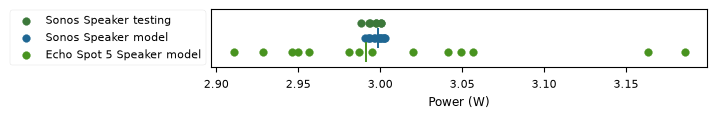

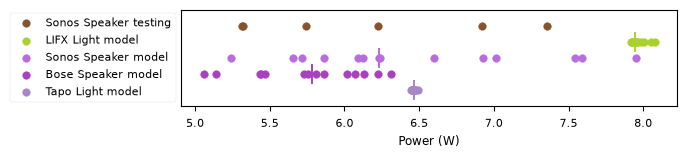

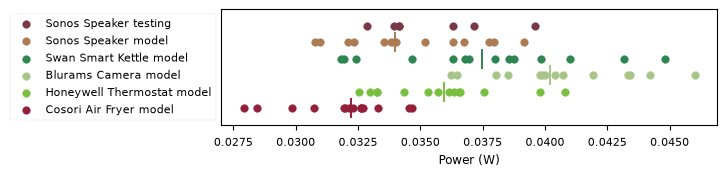

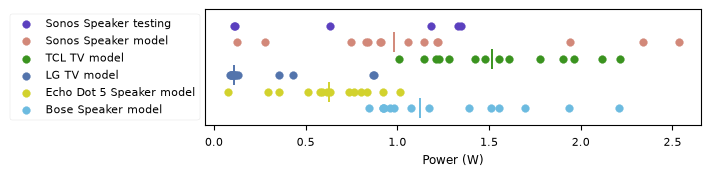

In [ ]:
# | label: confused with

# for a device, see what other devices it is confused with
# [ for device, class_ in all.classes.items() if class]


# lifx = all.devices[2]
# 1 function for getting data either training or otherwise to plot.


# 1 function to actually plot it


plot_metrics(summary_idle_mean, confused_with(summary_idle_mean, "sonos", State.IDLE))

plot_metrics(
    summary_active_mean, confused_with(summary_active_mean, "sonos", State.ACTIVE)
)

# TODO mode to plot overlapping distributions
# TODO randomly selected windows, are there startup effects?

std_idle = common([State.IDLE], [Metric.STD])
std_active = common([State.ACTIVE], [Metric.STD])
plot_metrics(std_idle, confused_with(std_idle, "sonos", State.IDLE))

plot_metrics(std_active, confused_with(std_active, "sonos", State.ACTIVE))
plt.show()

0.7934259633340516
0.915438727938728


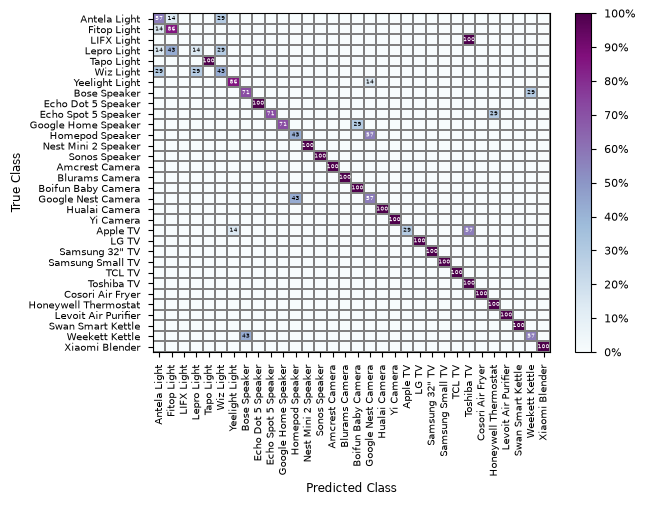

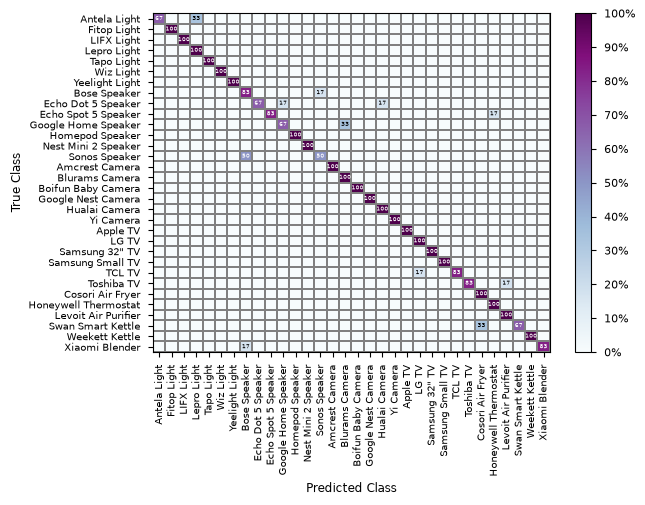

In [ ]:
# | label: mu sigma

mu_sigma = Experiment(
    ["SafeNetIoT"],
    [State.IDLE],
    [Metric.MEAN, Metric.STD],
    Classifier.Median,
)

mu_sigma.graph_confusion_matrix()
print(mu_sigma.f1_macro_average)

mu_sigma = Experiment(
    ["SafeNetIoT"],
    [State.ACTIVE],
    [Metric.MEAN, Metric.STD],
    Classifier.Median,
)

mu_sigma.graph_confusion_matrix()
print(mu_sigma.f1_macro_average)

State,Macro Average F1 score,Devices with Precision > 90%
Idle,0.717,19 / 32
Average,0.857,21 / 32


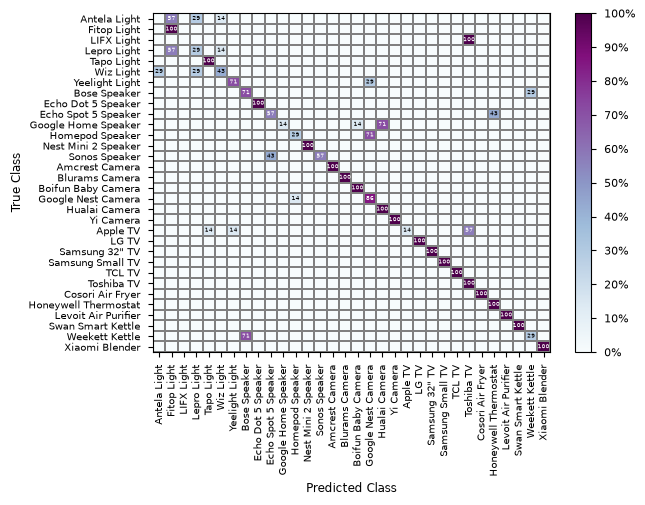

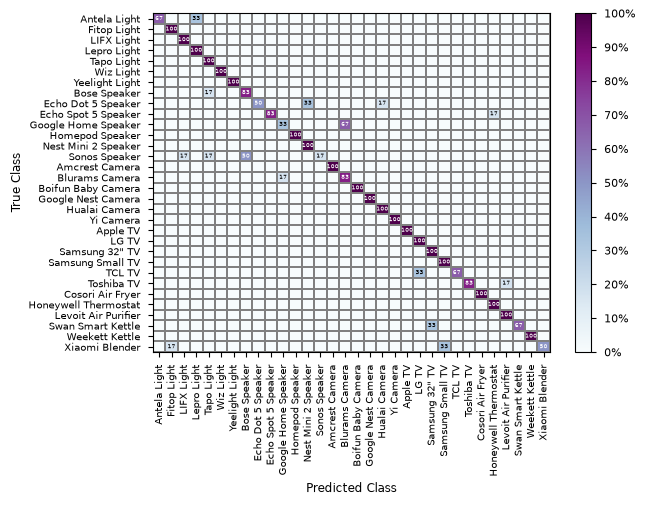

In [ ]:
# | label: confusion matrix
idle = Experiment(
    ["SafeNetIoT"],
    [State.IDLE],
    [Metric.MEAN],
    Classifier.Median,
)
idle.graph_confusion_matrix()

active = Experiment(
    ["SafeNetIoT"],
    [State.ACTIVE],
    [Metric.MEAN],
    Classifier.Median,
)
active.graph_confusion_matrix()
mean = pd.DataFrame(
    data={
        "Macro Average F1 score": [idle.f1_macro_average, active.f1_macro_average],
        "Devices with Precision > 90%": [
            f"{len([score for score in idle.precision.values() if score >= 0.9])} / {len(idle.devices())}",
            f"{len([score for score in active.precision.values() if score >= 0.9])} / {len(active.devices())}",
        ],
    },
    index=["Idle", "Average"],
)
mean.columns.name = "State"
await typst_table(
    mean.style.format(precision=3),
    "mean",
)
plt.show()

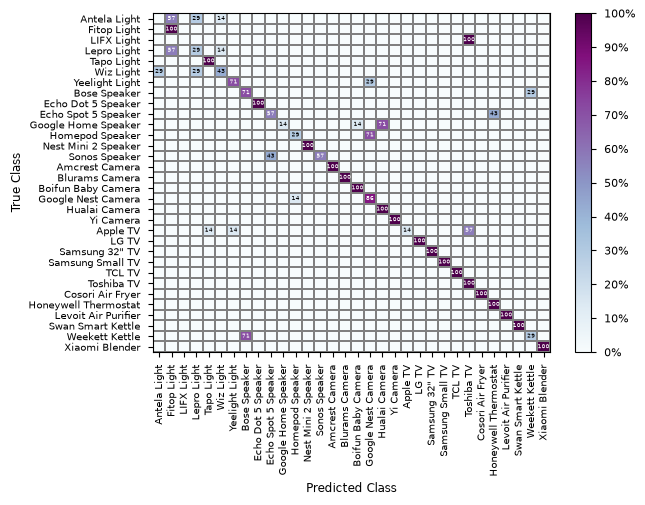

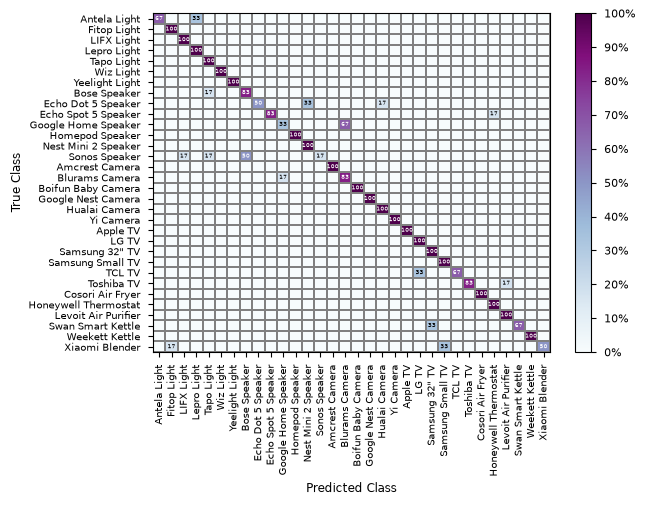

In [ ]:
# | label: fft

fft = Experiment(
    ["SafeNetIoT"],
    [State.IDLE],
    [Metric.FFT],
    Classifier.Median,
)

fft.graph_confusion_matrix()

fft_both = Experiment(
    ["SafeNetIoT"],
    [State.ACTIVE],
    [Metric.MEAN, Metric.FFT],
    Classifier.Median,
)

fft_both.graph_confusion_matrix()

In [9]:
# | label: combined

both = Experiment(
    ["SafeNetIoT"],
    states=[State.IDLE, State.ACTIVE],
    metrics=[Metric.MEAN],
    classify_by=Classifier.Median,
)

# both.f1_macro_average

both_mu_sigma = Experiment(
    ["SafeNetIoT"],
    states=[State.IDLE, State.ACTIVE],
    metrics=[Metric.MEAN, Metric.STD],
    classify_by=Classifier.Median,
)

# both_mu_sigma.f1_macro_average

# accuracy at picking state, assumes only 2 states

state: dict[State | str, list[float]] = {state: [0.0, 0.0] for state in State}
state["overall"] = [0, 0]
state["overall"][0] = both_mu_sigma.f1_macro_average

state["overall"][1] = both_mu_sigma.f1_macro_average


for i, model in enumerate([both, both_mu_sigma]):
    for real_data, counter in model.classes.items():
        total = 0
        for predicted_data, count in counter.items():
            if real_data.state == predicted_data.state:
                total += count

        state[real_data.state][i] += total / counter.total() / len(model.devices())

both_table = pd.DataFrame(
    data=state, index=[f"{mean_fancy}", f"{mean_fancy} and {std_fancy}"]
)
# both.columns
both_table.columns = both_table.columns.str.capitalize()
await typst_table(
    both_table.style.format(precision=3),
    "both",
)

# graph_confusion_matrix(both)

,Active,Idle,Overall
μ,0.859,0.937,0.816
μ and σ,0.911,0.990,0.816


None 0.7934259633340516 0.0


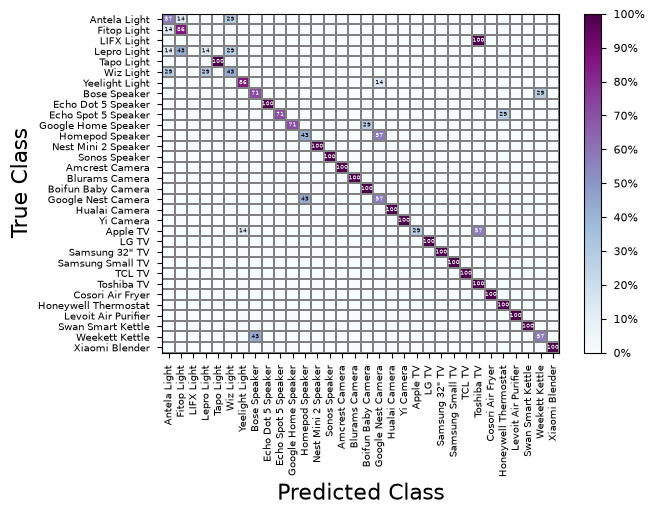

0 0.7934259633340516 0.0


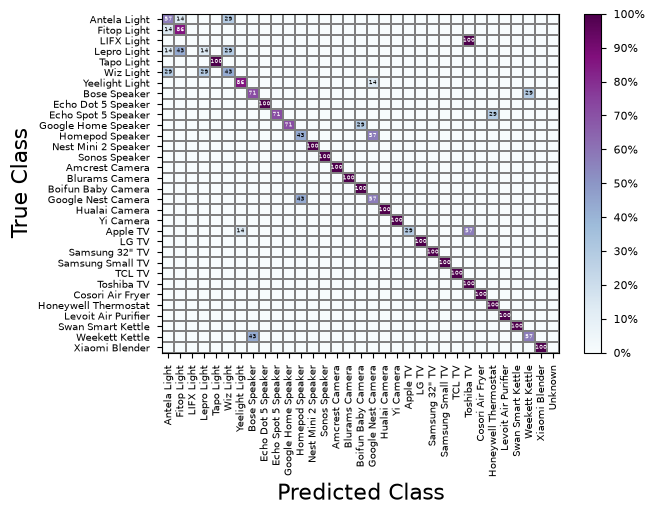

1 0.770085292279282 0.044642857142857144


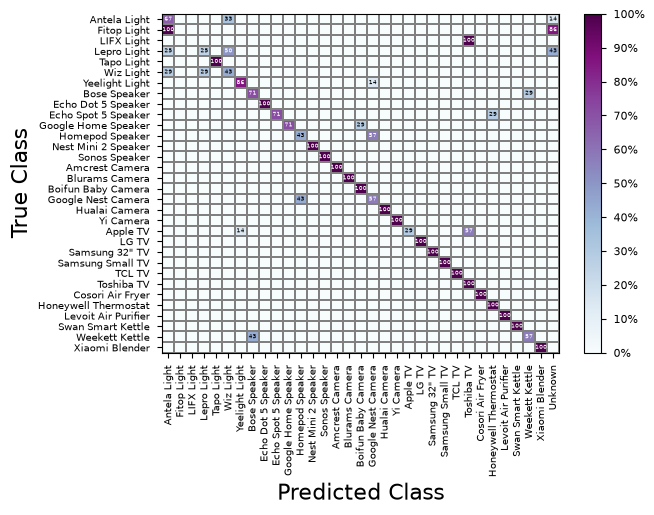

2 0.6991302139260631 0.20982142857142858


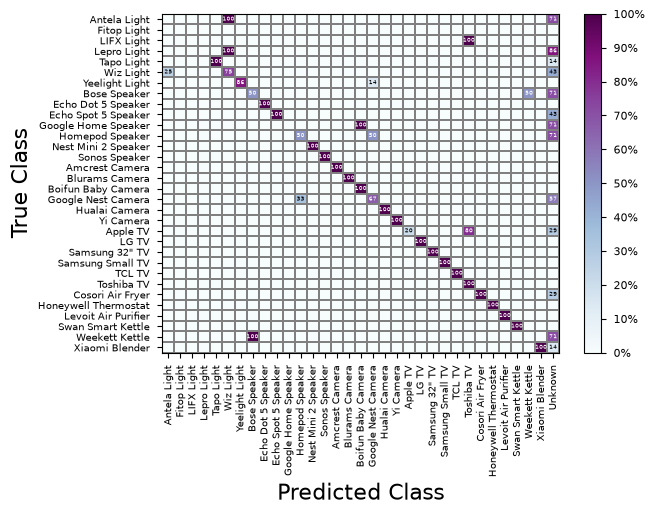

3 0.6927624458874458 0.29910714285714285


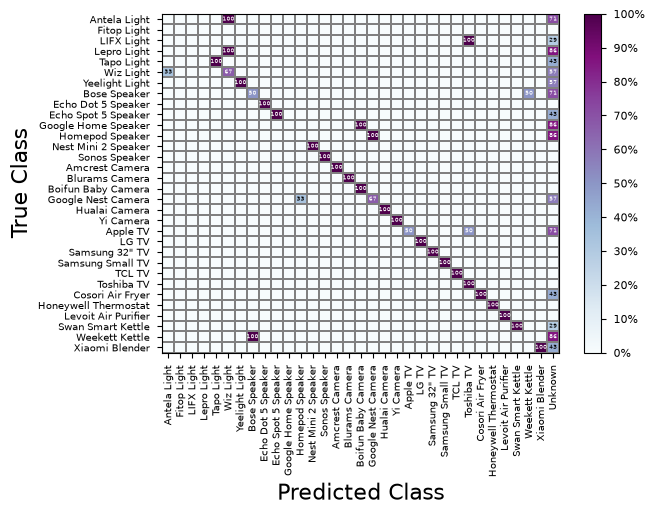

4 0.7209821428571429 0.3169642857142857


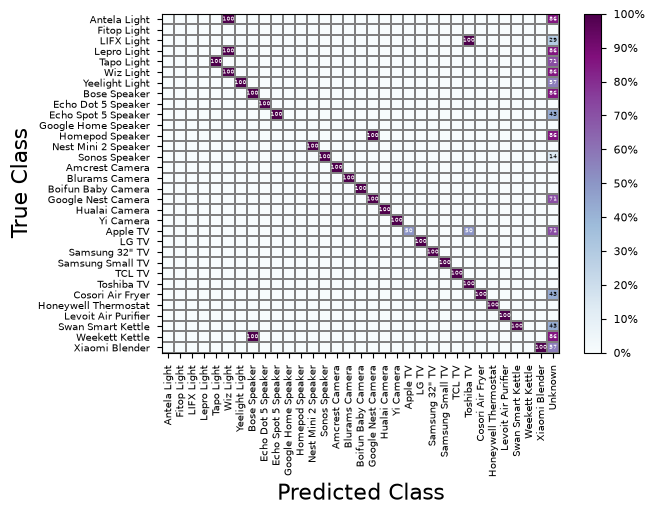

In [ ]:
for threshold in [None, 0, 1, 2, 3, 4]:
    exp = Experiment(
        ["SafeNetIoT"],
        [State.IDLE],
        [Metric.MEAN, Metric.STD],
        Classifier.Median,
        threshold=threshold,
        # include=["appletv", "samsungtv", "cosori"],
    )
    exp.graph_confusion_matrix()
    # print(exp.f1_scores.values())
    print(threshold, exp.f1_macro_average, np.mean(list(exp.unknown.values())))
    plt.show()
# print(exp.classes)
# print(len(exp.devices), len(exp.data))
# # nice_names = [print(data) for data in exp.data]
# print(exp.data)
# # display(
# #     pd.DataFra  me(
# #         data=exp.confusion_matrix, columns=nice_names
# #     ).style  # .format(precision=2)
# # )
# print(exp.f1_scores)

# TODO version of f1 including and excluding unknowns

In [20]:
# Construct summary table for report. Should show the performance of a range of models in a range of situations
data = {}

models = {
    "$\\mu$": partial(Experiment, metrics=[Metric.MEAN], classify_by=Classifier.Median),
    "$\\mu \\ \\sigma$": partial(
        Experiment, metrics=[Metric.MEAN, Metric.STD], classify_by=Classifier.Median
    ),
    # "$\\mu$ centroid": partial(
    #     Experiment, metrics=[Metric.MEAN], classify_by=Classifier.Centroid
    # ),
    # "$\\mu \\ \\sigma$ centroid": partial(
    # Experiment, metrics=[Metric.MEAN, Metric.STD], classify_by=Classifier.Centroid
    # ),
    # "$\\mu \\ \\sigma$ with distance based rejection": partial(
    # common, metrics=[Metric.MEAN, Metric.STD], threshold=1
    # ),
}

environments = {
    "SafeNetIoT Idle": (["SafeNetIoT"], [State.IDLE]),
    "SafeNetIoT Active": (["SafeNetIoT"], [State.ACTIVE]),
    "SafeNetIoT Full": (["SafeNetIoT"], [State.IDLE, State.ACTIVE]),
    "My Data": (["My Data"], [State.IDLE]),
    # "Combined Dataset": (["SafeNetIoT", "My Data"], [State.IDLE, State.ACTIVE]),
}

reports = {
    "Macro Average F1 Score": lambda exp: exp.f1_macro_average,
    "Traces with Precision > 90%": lambda exp: f"{len([score for score in exp.precision.values() if score >= 0.9])} / {len(exp.data())}",
    #  "Unknown rate": # lambda exp: np.mean(list(exp.unknown.values())),
}

# all = [
#     map(prop, exps)
#     for exps in [
#         [
#             settings(datasets=datasets, states=states)  # type: ignore
#             # idk why pylance is ignore the new parameter
#             for datasets, states in environments.values()
#         ]
#         for settings in models.values()
#     ]
#     for prop in reports.values()
# ]

all = [[1, 2, 3, 4]]

data = pd.DataFrame(
    all,
    index=pd.MultiIndex.from_product(
        [
            models,
            reports,
        ],
        names=["Features", "Property"],
    ),
    columns=pd.MultiIndex.from_product(
        [["Dataset"], environments],
    ),
)
# data.columns.name = "Model"
await typst_table(data.style.format(precision=3), "evaluation", collapse_header=True)

<tr>
<th class="blank"> </th>
<th class="blank level1"> </th>
<th class="col_heading level1 col0" id="T_a9ded_level1_col0">SafeNetIoT Idle</th>
<th class="col_heading level1 col1" id="T_a9ded_level1_col1">SafeNetIoT Active</th>
<th class="col_heading level1 col2" id="T_a9ded_level1_col2">SafeNetIoT Full</th>
<th class="col_heading level1 col3" id="T_a9ded_level1_col3">My Data</th>
</tr>
<tr>
<th class="index_name level0">Features</th>
<th class="index_name level1">Property</th>
<th class="blank col0"> </th>
<th class="blank col1"> </th>
<th class="blank col2"> </th>
<th class="blank col3"> </th>
</tr>


2


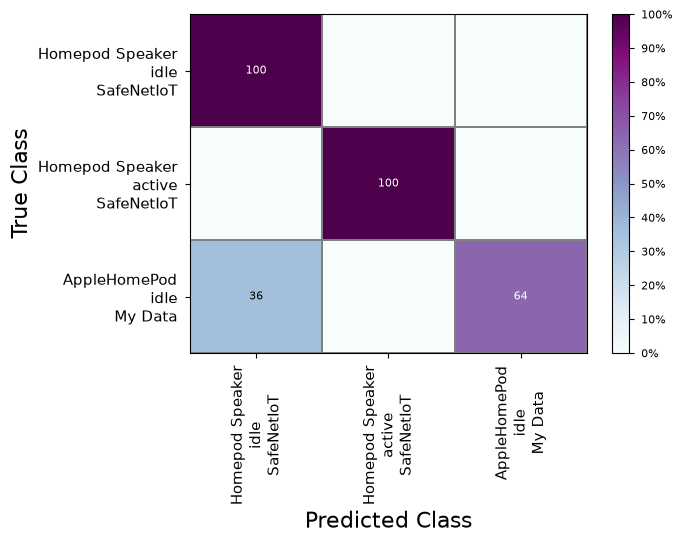

In [ ]:
# Compare the homepod across both datasets

homepods = Experiment(
    ["SafeNetIoT", "My Data"],
    [State.IDLE, State.ACTIVE],
    [Metric.MEAN, Metric.STD],
    Classifier.Median,
    include=["homepod", "AppleHomePod"],
)

print(len(homepods.devices()))
homepods.graph_confusion_matrix(multiline_labels=True)
# graph_confusion_matrix

In [13]:
# dataset table
table = pd.DataFrame(
    data={
        "SafeNetIOT": ["32", "40 minutes", "Idle, Active"],
        "My Dataset": [6, "22 hours", "Idle"],
    },
    index=["Devices", "Trace length", "States"],
)
await typst_table(table.style, "data")

,SafeNetIOT,My Dataset
Devices,32,6
Trace length,40 minutes,22 hours
States,"Idle, Active",Idle
